# Data Inspection and Processing

I want to load the astronomy data here, inspect it, and preprocess it for analysis.

### Load Data:

First make sure to download the data file from the AstroNN: https://astronn.readthedocs.io/en/latest/galaxy10.html

In [1]:

from pathlib import Path

# Find the project directory by searching the current directory and its parents
# Assumes the data file is located in a "data/" subdirectory of the project root
filename = "Galaxy10_DECals.h5"

project_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / filename).exists()),
    None
)

if project_root is None:
    raise FileNotFoundError(f"Could not find data/{filename}")

data_path = project_root / "data" / filename

print(f"Project directory: {project_root}")
print(f"Data path: {data_path}")
print(f"File exists: {data_path.exists()}")

Project directory: /home/hyrum/Projects/ML-FinalProject/ML_finalproj
Data path: /home/hyrum/Projects/ML-FinalProject/ML_finalproj/data/Galaxy10_DECals.h5
File exists: True


In [3]:
import h5py
import numpy as np
import torch

with h5py.File(data_path, "r") as f:
    print(f['images'][0])
    train_dataset = torch.from_numpy(f['images'][:])

    # Display the datasets stored in the HDF5 file
    print("Datasets:", list(f.keys()))

    # Inspect the structure of each dataset
    for key in f.keys():
        print(f"\nDataset: {key}")
        print("Shape:", f[key].shape)
        print("Data type:", f[key].dtype)

[[[68 19 23]
  [58 17 33]
  [40 16 40]
  ...
  [51 46 43]
  [40 41 33]
  [28 38 30]]

 [[61 40 37]
  [52 43 44]
  [29 39 41]
  ...
  [28 30 42]
  [28 32 35]
  [33 40 33]]

 [[30 31 25]
  [24 41 33]
  [15 45 33]
  ...
  [21 35 48]
  [25 35 45]
  [37 41 40]]

 ...

 [[28 32 35]
  [27 31 32]
  [42 44 43]
  ...
  [20 37 27]
  [19 40 21]
  [27 50 24]]

 [[22 36 37]
  [19 29 30]
  [33 37 38]
  ...
  [17 35 35]
  [17 35 21]
  [26 45 17]]

 [[18 39 40]
  [14 28 29]
  [24 30 30]
  ...
  [20 35 56]
  [27 37 36]
  [28 36 15]]]
Datasets: ['ans', 'dec', 'images', 'pxscale', 'ra', 'redshift']

Dataset: ans
Shape: (17736,)
Data type: uint8

Dataset: dec
Shape: (17736,)
Data type: float64

Dataset: images
Shape: (17736, 256, 256, 3)
Data type: uint8

Dataset: pxscale
Shape: (17736,)
Data type: float64

Dataset: ra
Shape: (17736,)
Data type: float64

Dataset: redshift
Shape: (17736,)
Data type: float64


Attempt to emulate the VAE from class.

In [4]:
import numpy as np
import torch.nn as nn
from torch.optim import Adam
import matplotlib.pyplot as plt
import matplotlib
#matplotlib.use('Agg') 
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from mpl_toolkits.axes_grid1 import ImageGrid
from torchvision.utils import save_image, make_grid
from PIL import Image

In [5]:
# create a transform to apply to each datapoint
transform = transforms.Compose([transforms.ToTensor()])

# create train and test dataloaders
batch_size = 100
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
#test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NaNs: 0
Infs: 0
Min: 0.0
Max: 255.0
Mean: 41.107643127441406
Std: 30.11846160888672


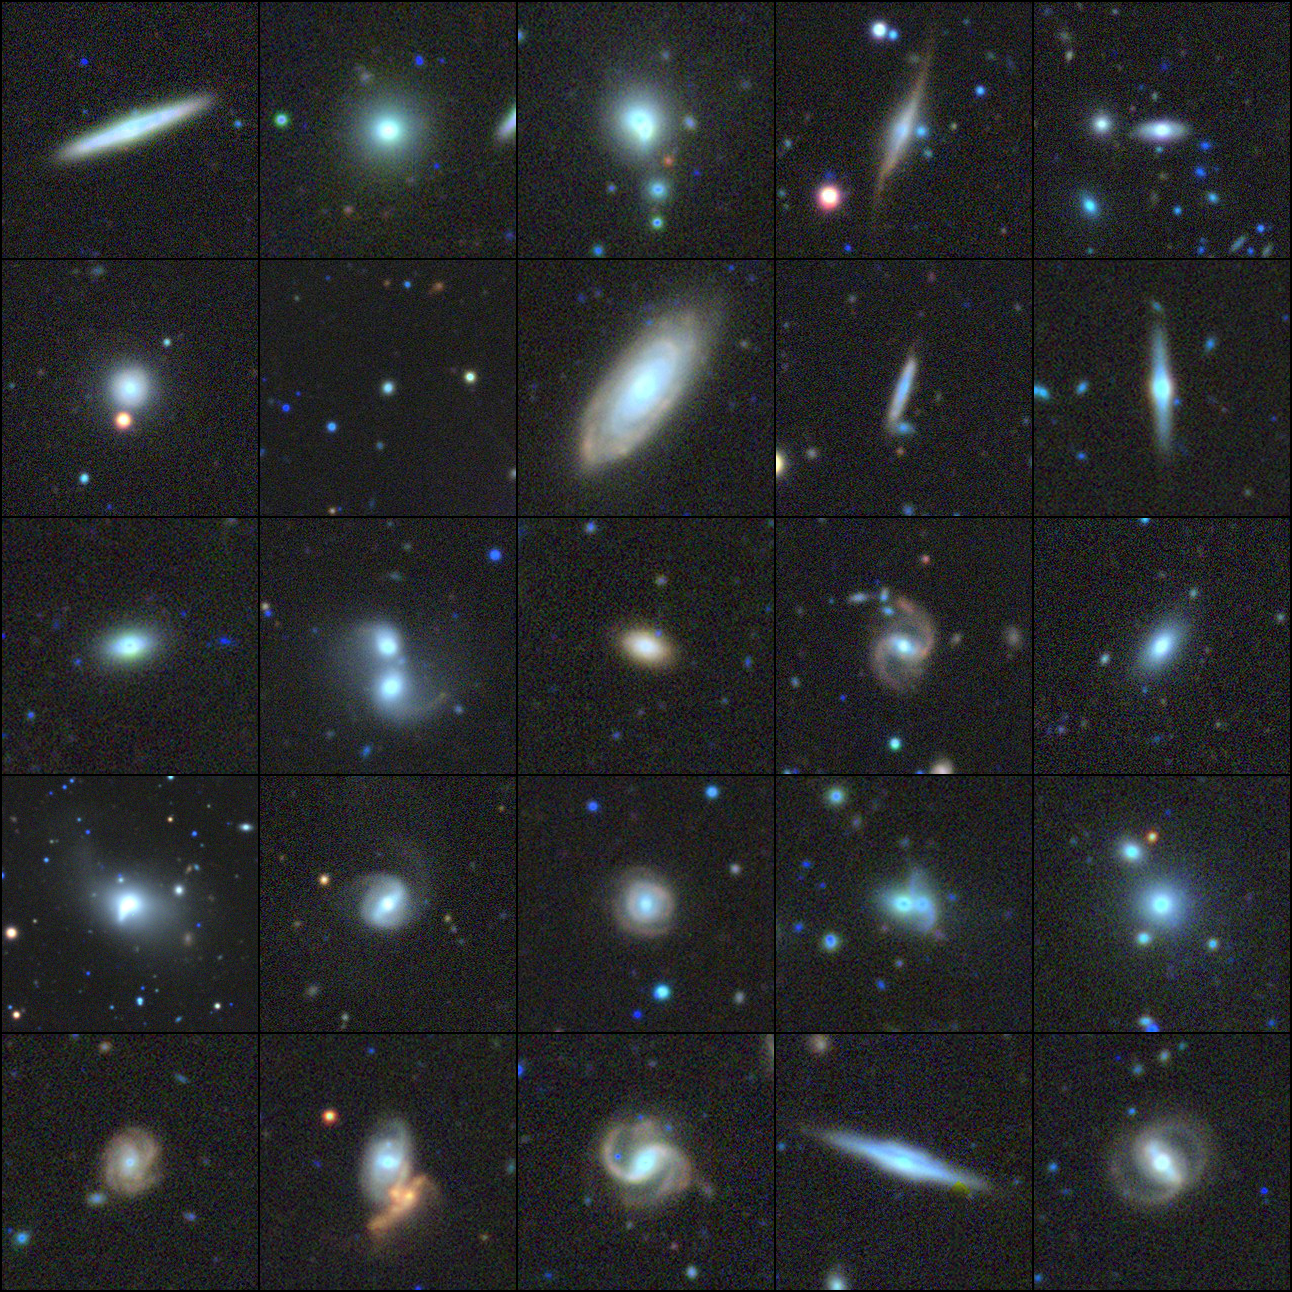

In [34]:
# Get one batch
images = next(iter(train_loader))

if isinstance(images, (list, tuple)):
    x = images[0]
else:
    x = images

x = x.float()

print("NaNs:", torch.isnan(x).sum().item())
print("Infs:", torch.isinf(x).sum().item())
print("Min:", x.min().item())
print("Max:", x.max().item())
print("Mean:", x.mean().item())
print("Std:", x.std().item())

# Move to CPU and detach
images = images.cpu().detach()

# Convert NHWC -> NCHW (256, 256, 3 -> 3, 256, 256)
images = images.permute(0, 3, 1, 2)

# Map g, r, z -> RGB (z, r, g)
images = images[:, [2, 1, 0], :, :]

# Make a 5x5 grid
grid_img = make_grid(images[:25], nrow=5, padding=2)

# Convert CHW -> HWC and scale to [0, 255]
grid_np = (grid_img.permute(1, 2, 0).numpy()).astype('uint8')

# Convert to PIL image and display inline
pil_img = Image.fromarray(grid_np, mode='RGB')
display(pil_img)

In [7]:
class Encoder(nn.Module):

    def __init__(self, input_dim=256*256*3, hidden_dim=512, latent_dim=256):
        super(Encoder, self).__init__()

        self.linear1 = nn.Linear(input_dim, hidden_dim)
        self.linear2 = nn.Linear(hidden_dim, hidden_dim)
        self.mean = nn.Linear(hidden_dim, latent_dim)
        self.var = nn.Linear (hidden_dim, latent_dim)
        self.LeakyReLU = nn.LeakyReLU(0.2)
        self.training = True

    def forward(self, x):
        x = self.LeakyReLU(self.linear1(x))
        x = self.LeakyReLU(self.linear2(x))

        mean = self.mean(x)
        log_var = self.var(x)
        return mean, log_var

In [8]:
class Decoder(nn.Module):

    def __init__(self, output_dim=256*256*3, hidden_dim=512, latent_dim=256):
        super(Decoder, self).__init__()

        self.linear2 = nn.Linear(latent_dim, hidden_dim)
        self.linear1 = nn.Linear(hidden_dim, hidden_dim)
        self.output = nn.Linear(hidden_dim, output_dim)
        self.LeakyReLU = nn.LeakyReLU(0.2)

    def forward(self, x):
        x = self.LeakyReLU(self.linear2(x))
        x = self.LeakyReLU(self.linear1(x))

        x_hat = torch.sigmoid(self.output(x))
        return x_hat

In [9]:
class VAE(nn.Module):

    def __init__(self, input_dim=256*256*3, hidden_dim=400, latent_dim=200, device=device):
        super(VAE, self).__init__()

        # encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, latent_dim),
            nn.LeakyReLU(0.2)
            )

        # latent mean and variance
        self.mean_layer = nn.Linear(latent_dim, 2)
        self.logvar_layer = nn.Linear(latent_dim, 2)

        # decoder
        self.decoder = nn.Sequential(
            nn.Linear(2, latent_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(latent_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
            )

    def encode(self, x):
        x = self.encoder(x)
        mean, logvar = self.mean_layer(x), self.logvar_layer(x)
        return mean, logvar

    def reparameterization(self, mean, var):
        epsilon = torch.randn_like(var).to(device)
        z = mean + var*epsilon
        return z

    def decode(self, x):
        return self.decoder(x)

    def forward(self, x):
        mean, logvar = self.encode(x)
        z = self.reparameterization(mean, logvar)
        x_hat = self.decode(z)
        return x_hat, mean, log_var

    def forward(self, x):
        mean, log_var = self.encode(x)
        z = self.reparameterization(mean, torch.exp(0.5 * log_var))
        x_hat = self.decode(z)
        return x_hat, mean, log_var

In [10]:
model = VAE().to(device)
optimizer = Adam(model.parameters(), lr=1e-3)

In [27]:
def loss_function(x, x_hat, mean, log_var):

    reproduction_loss = nn.functional.mse_loss(
        x_hat, x, reduction='sum'
    )

    KLD = -0.5 * torch.sum(
        1 + log_var - mean.pow(2) - log_var.exp()
    )

    return reproduction_loss + KLD

In [32]:
def train(model, optimizer, epochs, device, x_dim=256*256*3):
    model.train()

    for epoch in range(epochs):
        overall_loss = 0
        total_samples = 0

        for batch_idx, x in enumerate(train_loader):

            # Move images to device
            x = x.to(device).float() / 255.0

            # Flatten images: (B, 256, 256, 3) -> (B, 196608)
            x = x.reshape(x.shape[0], x_dim)

            

            optimizer.zero_grad()

            # Forward pass
            x_hat, mean, log_var = model(x)

            print("Mean finite:", torch.isfinite(mean).all().item())
            print("Log_var finite:", torch.isfinite(log_var).all().item())
            
            print("Mean range:", mean.min().item(), mean.max().item())
            print("Log_var range:", log_var.min().item(), log_var.max().item())
            
            # Calculate VAE loss
            loss = loss_function(x, x_hat, mean, log_var)

            # Backpropagation
            loss.backward()
            optimizer.step()

            overall_loss += loss.item()
            total_samples += x.shape[0]

        print(
            "\tEpoch", epoch + 1,
            "\tAverage Loss:", overall_loss / total_samples
        )

    return overall_loss

In [33]:
train(model, optimizer, epochs=50, device=device)

Mean finite: False
Log_var finite: False
Mean range: nan nan
Log_var range: nan nan
Mean finite: False
Log_var finite: False
Mean range: nan nan
Log_var range: nan nan
Mean finite: False
Log_var finite: False
Mean range: nan nan
Log_var range: nan nan
Mean finite: False
Log_var finite: False
Mean range: nan nan
Log_var range: nan nan
Mean finite: False
Log_var finite: False
Mean range: nan nan
Log_var range: nan nan
Mean finite: False
Log_var finite: False
Mean range: nan nan
Log_var range: nan nan
Mean finite: False
Log_var finite: False
Mean range: nan nan
Log_var range: nan nan
Mean finite: False
Log_var finite: False
Mean range: nan nan
Log_var range: nan nan
Mean finite: False
Log_var finite: False
Mean range: nan nan
Log_var range: nan nan
Mean finite: False
Log_var finite: False
Mean range: nan nan
Log_var range: nan nan
Mean finite: False
Log_var finite: False
Mean range: nan nan
Log_var range: nan nan
Mean finite: False
Log_var finite: False
Mean range: nan nan
Log_var range: 

KeyboardInterrupt: 